# Dependency Setup

In [2]:
import os
import IPython

from transformers import TrainingArguments
print(TrainingArguments.__module__)

import pandas as pd
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch
from datasets import Dataset

import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import numpy as np

transformers.training_args


In [3]:
df = pd.read_csv('5_INPUT_preprocessed_relevant_user_comments.csv')
print(len(df))
df.head()

8699


,comment,replies,date,user_name,source_file,link,manual_label,relevansi,clean_text
0,Prediksi Menteri Keuangan Sri Mulyani Indrawat...,"['Tidak butuh prediksi. Tapi solusi', 'Tdk usa...",2025-04-04T07:16:51Z,@kontantv,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,netral,relevan,prediksi menteri uang sri mulyani indrawati se...
1,korupsi dan pajak yg tinggi lebih berbahaya dr...,[],2025-04-29T10:38:49Z,@victorferry5496,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korupsi pajak bahaya dr tarrif trumph korupsi ...
2,Korups yg di indonesia yg.bikom.parah makanya ...,[],2025-04-29T02:33:56Z,@zannariabintang4812,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,korups indonesia ygbikomparah prabowo hukum ko...
3,Maap buk di putus aja hububgan jikala tk teken...,[],2025-04-28T13:11:38Z,@fahmiidris4355,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,maap buk putus hububgan jikala tk teken gitu k...
4,Waduh🫠,[],2025-04-27T02:29:54Z,@PolitikaHistoria,BERITA_KONTAN_user_comments.csv,https://www.youtube.com/watch?v=p0NTgOcwj3k,negatif,relevan,NaN


In [4]:
# create copy of df for indobert, mbert, and bert base
df_ib = df.copy()
df_mb = df.copy()
df_bb = df.copy()

# indoBERT

## set encoder

In [24]:
# --- Encode Labels ---
label_encoder = LabelEncoder()
df_ib['labels'] = label_encoder.fit_transform(df_ib['manual_label'])  # Encode labels
print(label_encoder.classes_)

['negatif' 'netral' 'positif']


## train data

In [10]:
# --- Tokenizer ---
tokenizer = BertTokenizer.from_pretrained('indobenchmark/indobert-base-p1')

# --- Tokenization Function ---
def tokenize(batch):
    batch['text'] = [str(t) for t in batch['text']]
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

# --- Stratified KFold ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Prepare to collect metrics
results = []

X = df_ib['clean_text'].values
y = df_ib['labels'].values

fold = 1
for train_idx, val_idx in skf.split(X, y):
    print(f"\n=== Fold {fold} ===")

    # Split data
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Over sampling pada data training
    ros = RandomOverSampler(random_state=42)
    X_train_resampled, y_train_resampled = ros.fit_resample(X_train.reshape(-1, 1), y_train)
    X_train_resampled = X_train_resampled.flatten()  # Kembalikan ke array 1D

    # Convert to Dataset
    train_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_train_resampled, 'labels': y_train_resampled}))
    val_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_val, 'labels': y_val}))

    # Tokenization
    train_dataset = train_dataset.map(tokenize, batched=True)
    val_dataset = val_dataset.map(tokenize, batched=True)
    train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
    val_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

    # Model
    model = BertForSequenceClassification.from_pretrained('indobenchmark/indobert-base-p1', num_labels=3)

    # Training Arguments
    training_args = TrainingArguments(
        output_dir=f'./results/fold_{fold}',
        logging_strategy="no",  # Disable logging to make it clean
        num_train_epochs=2,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        eval_strategy="epoch",
        save_strategy="no",
        load_best_model_at_end=False,
    )

    # Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
    )

    # Train
    trainer.train()

    # Predict
    preds_output = trainer.predict(val_dataset)
    y_pred = np.argmax(preds_output.predictions, axis=1)

    # Metrics
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro')
    precision = precision_score(y_val, y_pred, average='macro')
    recall = recall_score(y_val, y_pred, average='macro')

    print(f"Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

    results.append({
        "fold": fold,
        "accuracy": acc,
        "f1_score": f1,
        "precision": precision,
        "recall": recall
    })

    fold += 1


=== Fold 1 ===


Map:   0%|          | 0/18405 [00:00<?, ? examples/s]

Map:   0%|          | 0/1740 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,No log,0.490446
2,No log,0.483337


Accuracy: 0.9397 | F1: 0.6289 | Precision: 0.6964 | Recall: 0.6100

=== Fold 2 ===


... (16 outputs left out)

Map:   0%|          | 0/1739 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,No log,0.481791
2,No log,0.423543


Accuracy: 0.9454 | F1: 0.6543 | Precision: 0.7039 | Recall: 0.6422


## Results


indoBERT Oversampling Classification Report:
              precision    recall  f1-score   support

     negatif       0.96      0.98      0.97      1534
      netral       0.31      0.10      0.15        42
     positif       0.84      0.85      0.85       163

    accuracy                           0.95      1739
   macro avg       0.70      0.64      0.65      1739
weighted avg       0.93      0.95      0.94      1739



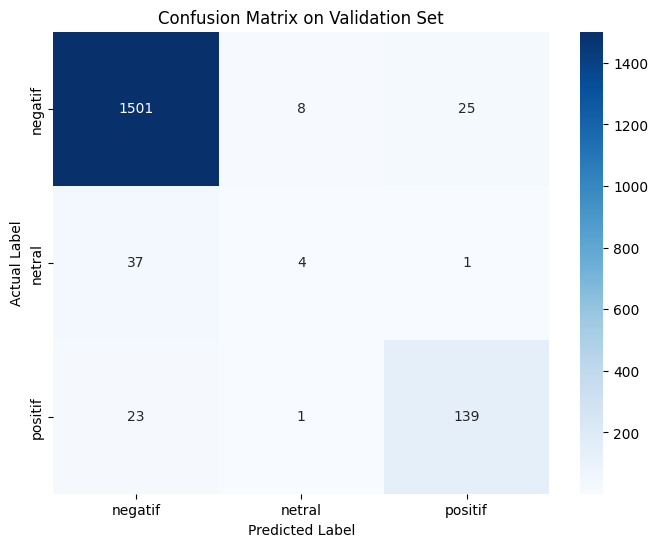

In [11]:
# Classification Report
print("\nindoBERT Oversampling Classification Report:")
print(classification_report(y_val, y_pred, target_names=label_encoder.classes_))

# Buat Confusion Matrix validasi
cm = confusion_matrix(y_val, y_pred, labels=[0,1,2])
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_.tolist(),
            yticklabels=label_encoder.classes_.tolist())
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()

In [12]:
# --- Overall Summary ---
df_ib_results = pd.DataFrame(results)
print("\nAverage Scores:")
print(df_ib_results.mean())


Average Scores:
fold         3.000000
accuracy     0.941718
f1_score     0.639688
precision    0.725851
recall       0.617694
dtype: float64


In [13]:
df_ib_results.head()

,fold,accuracy,f1_score,precision,recall
0,1,0.939655,0.628927,0.696422,0.610001
1,2,0.941954,0.642126,0.754061,0.609775
2,3,0.936207,0.598377,0.629154,0.584968
3,4,0.945402,0.674688,0.845728,0.641563
4,5,0.945371,0.654322,0.703893,0.642162


# mBERT

## set encoder

In [5]:
# --- Encode Labels ---
label_encoder_mb = LabelEncoder()
df_mb['labels'] = label_encoder_mb.fit_transform(df_mb['manual_label'])  # Encode labels
print(label_encoder_mb.classes_)

['negatif' 'netral' 'positif']


## train data

In [6]:
# --- Tokenizer ---
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')

# --- Tokenization Function ---
def tokenize(batch):
    batch['text'] = [str(t) for t in batch['text']]
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

# --- Stratified KFold ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Prepare to collect metrics
results = []

X = df_mb['clean_text'].values
y = df_mb['labels'].values

fold = 1
for train_idx, val_idx in skf.split(X, y):
    print(f"\n=== Fold {fold} ===")

    # Split data
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Over sampling pada data training
    ros = RandomOverSampler(random_state=42)
    X_train_resampled, y_train_resampled = ros.fit_resample(X_train.reshape(-1, 1), y_train)
    X_train_resampled = X_train_resampled.flatten()  # Kembalikan ke array 1D

    # Convert to Dataset
    train_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_train_resampled, 'labels': y_train_resampled}))
    val_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_val, 'labels': y_val}))

    # Tokenization
    train_dataset = train_dataset.map(tokenize, batched=True)
    val_dataset = val_dataset.map(tokenize, batched=True)
    train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
    val_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

    # Model
    model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-cased', num_labels=3)

    # Training Arguments
    training_args = TrainingArguments(
        output_dir=f'./results/fold_{fold}',
        logging_strategy="no",  # Disable logging to make it clean
        num_train_epochs=2,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        eval_strategy="epoch",
        save_strategy="no",
        load_best_model_at_end=False,
    )

    # Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
    )

    # Train
    trainer.train()

    # Predict
    preds_output = trainer.predict(val_dataset)
    y_pred = np.argmax(preds_output.predictions, axis=1)

    # Metrics
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro')
    precision = precision_score(y_val, y_pred, average='macro')
    recall = recall_score(y_val, y_pred, average='macro')

    print(f"Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

    results.append({
        "fold": fold,
        "accuracy": acc,
        "f1_score": f1,
        "precision": precision,
        "recall": recall
    })

    fold += 1


=== Fold 1 ===


Map:   0%|          | 0/18405 [00:00<?, ? examples/s]

Map:   0%|          | 0/1740 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,No log,1.167813
2,No log,1.116986


/opt/anaconda3/envs/pi_sentiment_analysis/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


... (20 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,No log,1.142782
2,No log,1.092306


Accuracy: 0.0937 | F1: 0.0571 | Precision: 0.0312 | Recall: 0.3333


/opt/anaconda3/envs/pi_sentiment_analysis/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## results


mBERT Oversampling Classification Report:
              precision    recall  f1-score   support

     negatif       0.00      0.00      0.00      1534
      netral       0.00      0.00      0.00        42
     positif       0.09      1.00      0.17       163

    accuracy                           0.09      1739
   macro avg       0.03      0.33      0.06      1739
weighted avg       0.01      0.09      0.02      1739



/opt/anaconda3/envs/pi_sentiment_analysis/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/pi_sentiment_analysis/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/pi_sentiment_analysis/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

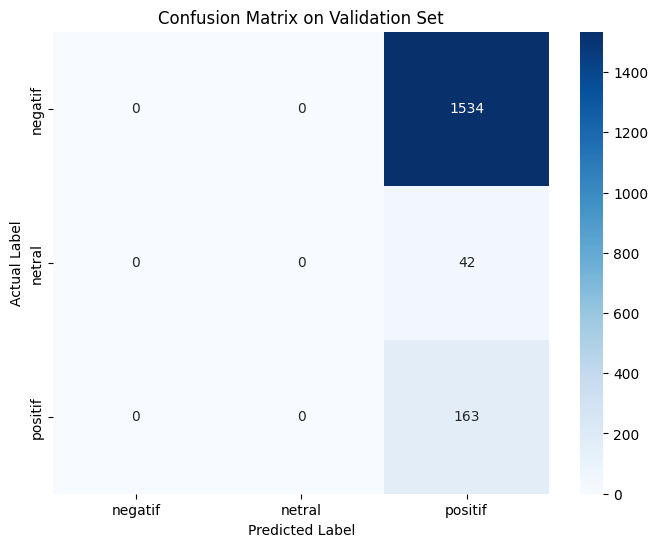

In [8]:
# Classification Report
print("\nmBERT Oversampling Classification Report:")
print(classification_report(y_val, y_pred, target_names=label_encoder_mb.classes_))

# Buat Confusion Matrix validasi
cm_mb = confusion_matrix(y_val, y_pred, labels=[0,1,2])
plt.figure(figsize=(8,6))
sns.heatmap(cm_mb, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder_mb.classes_.tolist(),
            yticklabels=label_encoder_mb.classes_.tolist())
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()

In [10]:
# --- Overall Summary ---
df_mb_results = pd.DataFrame(results)
print("\nAverage Scores:")
print(df_mb_results.mean())


Average Scores:
fold         3.000000
accuracy     0.158287
f1_score     0.105686
precision    0.102575
recall       0.367623
dtype: float64


In [13]:
df_mb_results.head()

,fold,accuracy,f1_score,precision,recall
0,1,0.093678,0.057103,0.031226,0.333333
1,2,0.094253,0.057423,0.031418,0.333333
2,3,0.415517,0.299348,0.387568,0.504784
3,4,0.094253,0.057423,0.031418,0.333333
4,5,0.093732,0.057133,0.031244,0.333333


# BERT base

## set encoder

In [5]:
# --- Encode Labels ---
label_encoder_bb = LabelEncoder()
df_bb['labels'] = label_encoder_bb.fit_transform(df_bb['manual_label'])  # Encode labels
print(label_encoder_bb.classes_)

['negatif' 'netral' 'positif']


## training

In [6]:
# --- Tokenizer ---
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# --- Tokenization Function ---
def tokenize(batch):
    batch['text'] = [str(t) for t in batch['text']]
    return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=128)

# --- Stratified KFold ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Prepare to collect metrics
results = []

X = df_bb['clean_text'].values
y = df_bb['labels'].values

fold = 1
for train_idx, val_idx in skf.split(X, y):
    print(f"\n=== Fold {fold} ===")

    # Split data
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Over sampling pada data training
    ros = RandomOverSampler(random_state=42)
    X_train_resampled, y_train_resampled = ros.fit_resample(X_train.reshape(-1, 1), y_train)
    X_train_resampled = X_train_resampled.flatten()  # Kembalikan ke array 1D

    # Convert to Dataset
    train_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_train_resampled, 'labels': y_train_resampled}))
    val_dataset = Dataset.from_pandas(pd.DataFrame({'text': X_val, 'labels': y_val}))

    # Tokenization
    train_dataset = train_dataset.map(tokenize, batched=True)
    val_dataset = val_dataset.map(tokenize, batched=True)
    train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
    val_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

    # Model
    model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=3)

    # Training Arguments
    training_args = TrainingArguments(
        output_dir=f'./results/fold_{fold}',
        logging_strategy="no",  # Disable logging to make it clean
        num_train_epochs=2,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        eval_strategy="epoch",
        save_strategy="no",
        load_best_model_at_end=False,
    )

    # Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
    )

    # Train
    trainer.train()

    # Predict
    preds_output = trainer.predict(val_dataset)
    y_pred = np.argmax(preds_output.predictions, axis=1)

    # Metrics
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='macro')
    precision = precision_score(y_val, y_pred, average='macro')
    recall = recall_score(y_val, y_pred, average='macro')

    print(f"Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

    results.append({
        "fold": fold,
        "accuracy": acc,
        "f1_score": f1,
        "precision": precision,
        "recall": recall
    })

    fold += 1

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]


=== Fold 1 ===


Map:   0%|          | 0/18405 [00:00<?, ? examples/s]

... (22 outputs left out)

Map:   0%|          | 0/1739 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,No log,0.623022
2,No log,0.456074


Accuracy: 0.9350 | F1: 0.6172 | Precision: 0.6658 | Recall: 0.6283


## results


BERT base Oversampling Classification Report:
              precision    recall  f1-score   support

     negatif       0.96      0.97      0.96      1534
      netral       0.29      0.05      0.08        42
     positif       0.75      0.87      0.81       163

    accuracy                           0.94      1739
   macro avg       0.67      0.63      0.62      1739
weighted avg       0.92      0.94      0.93      1739



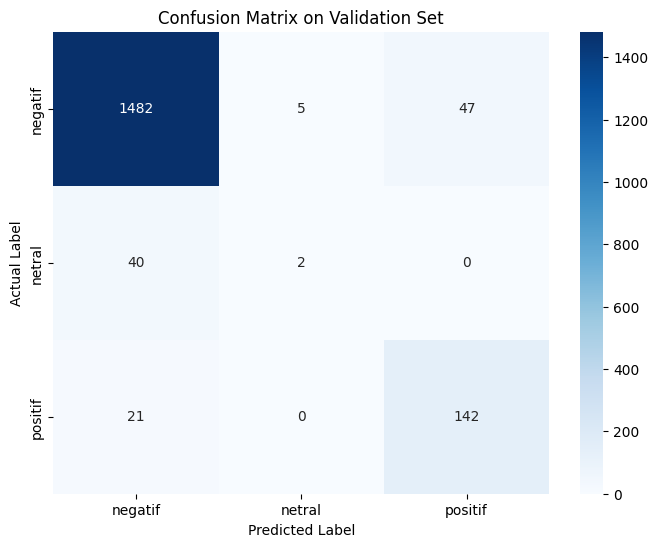

In [7]:
# Classification Report
print("\nBERT base Oversampling Classification Report:")
print(classification_report(y_val, y_pred, target_names=label_encoder_bb.classes_))

# Buat Confusion Matrix validasi
cm_bb = confusion_matrix(y_val, y_pred, labels=[0,1,2])
plt.figure(figsize=(8,6))
sns.heatmap(cm_bb, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder_bb.classes_.tolist(),
            yticklabels=label_encoder_bb.classes_.tolist())
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()

In [8]:
# --- Overall Summary ---
df_bb_results = pd.DataFrame(results)
print("\nAverage Scores:")
print(df_bb_results.mean())


Average Scores:
fold         3.000000
accuracy     0.767349
f1_score     0.510384
precision    0.533403
recall       0.572099
dtype: float64


In [9]:
df_bb_results.head()

,fold,accuracy,f1_score,precision,recall
0,1,0.093678,0.057103,0.031226,0.333333
1,2,0.929885,0.605385,0.617405,0.619181
2,3,0.939655,0.644345,0.670210,0.647549
3,4,0.938506,0.627843,0.682341,0.632135
4,5,0.935020,0.617242,0.665835,0.628295
